## Implementation of Linear regression using python

In [9]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt


## Load the dataset

In [10]:
DF1 = pd.read_csv("weight-height.csv")
DF1.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


### Standardize numerical features

In [11]:
col = ["Height","Weight"]
S1 = MinMaxScaler()
DF1[col]= S1.fit_transform(DF1[col])
DF1.head()


,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [12]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
X.shape

(10000, 1)

## Split the data into training and test set

In [13]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [14]:
# Create a linear regression model

model=LinearRegression()



Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [15]:
## Training  Linear regressions model 

In [16]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [17]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.0044380478890117024
0.06661867522708405
0.054480150433493836
0.8135299373473699
[3.54709605]
[0.10829265]


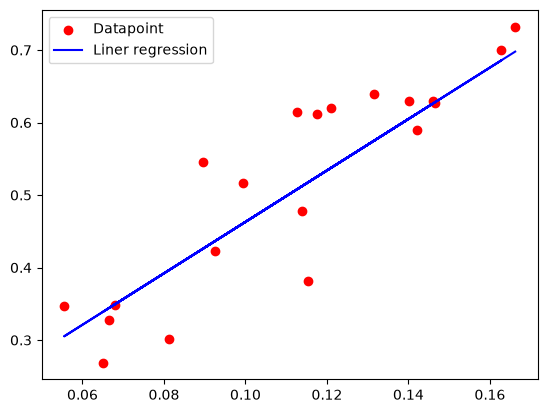

In [18]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [19]:
## Load the Height and weight  to indipendent and dependent variable 

In [20]:
DF2 = pd.read_csv("weight-height.csv")
X =  DF2['Height'].values.reshape(-1,1)
X.shape
Y = DF2["Weight"].values
print((X.shape))

(10000, 1)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [21]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [22]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [23]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)

(10000, 2)
(2, 10000)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [24]:
for i in range(iterations):
    y_pred=np.dot(X, theta)
    mse = mean_squared_error(Y, y_pred)
    mseh.append(mse)
    print(f"Iteration {i+1}: MSE = {mse}")
    gradient = np.dot(X.T, (y_pred - Y))/len(Y)
    theta -= learningrate*gradient

Iteration 1: MSE = 1.0
Iteration 2: MSE = 0.985809419277575
Iteration 3: MSE = 0.9719012311115264
Iteration 4: MSE = 0.9582698158899818
Iteration 5: MSE = 0.9449096658313463
Iteration 6: MSE = 0.9318153827588774
Iteration 7: MSE = 0.9189816759195508
Iteration 8: MSE = 0.9064033598463267
Iteration 9: MSE = 0.8940753522629599
Iteration 10: MSE = 0.8819926720305018
Iteration 11: MSE = 0.87015043713467
Iteration 12: MSE = 0.8585438627132649
Iteration 13: MSE = 0.847168259122846
Iteration 14: MSE = 0.8360190300438766
Iteration 15: MSE = 0.8250916706235781
Iteration 16: MSE = 0.8143817656557442
Iteration 17: MSE = 0.8038849877967698
Iteration 18: MSE = 0.7935970958171891
Iteration 19: MSE = 0.7835139328880019
Iteration 20: MSE = 0.7736314249011057
Iteration 21: MSE = 0.7639455788231487
Iteration 22: MSE = 0.7544524810821431
Iteration 23: MSE = 0.7451482959861835
Iteration 24: MSE = 0.7360292641736333
Iteration 25: MSE = 0.727091701094153
Iteration 26: MSE = 0.7183319955199544
Iteration 27: M

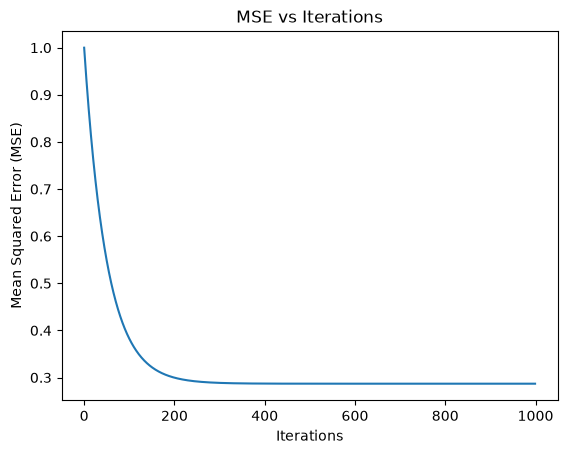

In [25]:
# Plot the MSE over iterations
plt.plot(range(iterations), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()

## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

Dataset Columns:
['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']

Intercept: 13.437805857525596

Regression Coefficients:
Distance_km: 3.0166
Preparation_Time_min: 0.9823
Traffic_Low: -11.0231
Traffic_Medium: -5.3496
Weather_Foggy: 6.1354
Weather_Rainy: 4.5319
Weather_Snowy: 9.2691
Weather_Windy: 1.8044

Model Evaluation
Mean Squared Error: 123.73180027915089
Mean Absolute Error: 6.772659346776476
R-squared Score: 0.7453778605148429

Actual vs Predicted Delivery Times:
   Actual Delivery Time  Predicted Delivery Time
0                   101                    96.15
1                    38                    36.55
2                   116                    54.00
3                    44                    40.85
4                    91                    49.78
5                    88                    79.97
6                    37                    39.39
7                    65 

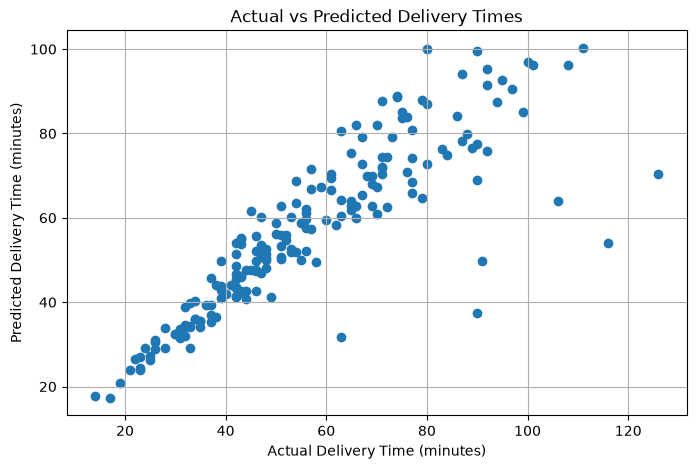

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load the dataset
df = pd.read_csv("Food_delivery_times.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Display available columns
print("Dataset Columns:")
print(df.columns.tolist())

# Rename common alternative column names to standard names
df = df.rename(columns={
    "Traffic_Level": "Traffic",
    "Weather_Conditions": "Weather",
    "Preparation Time (min)": "Preparation_Time_min",
    "Distance (km)": "Distance_km",
    "Delivery Time (min)": "Delivery_Time_min"
})

# Check required columns
required_columns = [
    "Distance_km",
    "Preparation_Time_min",
    "Traffic",
    "Weather",
    "Delivery_Time_min"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    print("\nMissing columns:", missing_columns)
    print("Please check the column names printed above.")
else:
    # Select independent and dependent variables
    X = df[
        ["Distance_km", "Preparation_Time_min", "Traffic", "Weather"]
    ].copy()

    y = df["Delivery_Time_min"]

    # Handle missing values
    data = pd.concat([X, y], axis=1).dropna()
    X = data.drop(columns=["Delivery_Time_min"])
    y = data["Delivery_Time_min"]

    # Encode categorical variables
    X = pd.get_dummies(
        X,
        columns=["Traffic", "Weather"],
        drop_first=True,
        dtype=int
    )

    # Split the dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # Create and train the Linear Regression model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predict delivery times
    y_pred = model.predict(X_test)

    # Display model parameters
    print("\nIntercept:", model.intercept_)

    print("\nRegression Coefficients:")
    for feature, coefficient in zip(X.columns, model.coef_):
        print(f"{feature}: {coefficient:.4f}")

    # Evaluate the model
    print("\nModel Evaluation")
    print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
    print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
    print("R-squared Score:", r2_score(y_test, y_pred))

    # Compare actual and predicted values
    results = pd.DataFrame({
        "Actual Delivery Time": y_test.values,
        "Predicted Delivery Time": y_pred
    })

    print("\nActual vs Predicted Delivery Times:")
    print(results.head(10).round(2))

    # Plot actual vs predicted delivery times
    plt.figure(figsize=(8, 5))
    plt.scatter(y_test, y_pred)
    plt.xlabel("Actual Delivery Time (minutes)")
    plt.ylabel("Predicted Delivery Time (minutes)")
    plt.title("Actual vs Predicted Delivery Times")
    plt.grid(True)
    plt.show()